In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from pathlib import Path
import matplotlib.pyplot as plt
import re

from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer
from deep_translator import GoogleTranslator

import spacy
translator = GoogleTranslator(source="pt", target="en")

In [2]:
data_path = Path("../data/processed")

csv_files = list(data_path.glob("*.csv"))

display(csv_files[0].name)

def read_datasets(datasets):
    dataframe = {}
    for dataset in datasets:
        filename = dataset.name
        dataframe[filename] = pd.read_csv(dataset)
    return dataframe

def convert_to_datetime(dataset, columns):
    for column in columns:
        dataset[column] = pd.to_datetime(dataset[column])
    return dataset

orders_dataset_columns_to_datetime = [
    "order_purchase_timestamp", 
    "order_approved_at", 
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date" 
    ]

order_items_dataset_columns_to_datetime = [
    "shipping_limit_date" 
    ]

order_reviews_dataset_columns_to_datetime = [
    "review_creation_date",
    "review_answer_timestamp" 
    ]

datasets = read_datasets(csv_files)

customers_dataset = datasets["olist_customers_dataset.csv"]
geolocation_dataset = datasets["olist_geolocation_dataset.csv"]
order_payments_dataset = datasets["olist_order_payments_dataset.csv"]
products_dataset = datasets["olist_products_dataset.csv"]
sellers_dataset = datasets["olist_sellers_dataset.csv"]
category_translation_dataset = datasets["product_category_name_translation.csv"]

orders_dataset = convert_to_datetime(dataset=datasets["olist_orders_dataset.csv"], columns=orders_dataset_columns_to_datetime)
orders_items_dataset = convert_to_datetime(dataset=datasets["olist_order_items_dataset.csv"], columns=order_items_dataset_columns_to_datetime)
reviews_dataset = convert_to_datetime(dataset=datasets["olist_order_reviews_dataset.csv"], columns=order_reviews_dataset_columns_to_datetime)

display(orders_dataset.dtypes)
display(orders_items_dataset.dtypes)
display(reviews_dataset.dtypes)

'olist_customers_dataset.csv'

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object

review_id                             str
order_id                              str
review_score                        int64
review_comment_title                  str
review_comment_message                str
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object

In [3]:
one_point_reviews = reviews_dataset[reviews_dataset["review_score"] == 1]
one_point_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
5,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,NaN,NaN,2018-04-13,2018-04-16 00:39:37
19,373cbeecea8286a2b66c97b1b157ec46,583174fbe37d3d5f0d6661be3aad1786,1,Não chegou meu produto,Péssimo,2018-08-15,2018-08-15 04:10:37
29,2c5e27fc178bde7ac173c9c62c31b070,0ce9a24111d850192a933fcaab6fbad3,1,NaN,Não gostei ! Comprei gato por lebre,2017-12-13,2017-12-16 07:14:07
32,58044bca115705a48fe0e00a21390c54,68e55ca79d04a79f20d4bfc0146f4b66,1,NaN,Sempre compro pela Internet e a entrega ocorre...,2018-04-08,2018-04-09 12:22:39
39,9fd59cd04b42f600df9f25e54082a8d1,3c314f50bc654f3c4e317b055681dff9,1,NaN,Nada de chegar o meu pedido.,2017-04-21,2017-04-23 05:37:03


In [4]:
one_point_reviews = one_point_reviews[one_point_reviews["review_comment_message"].notna()]
one_point_reviews

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
19,373cbeecea8286a2b66c97b1b157ec46,583174fbe37d3d5f0d6661be3aad1786,1,Não chegou meu produto,Péssimo,2018-08-15,2018-08-15 04:10:37
29,2c5e27fc178bde7ac173c9c62c31b070,0ce9a24111d850192a933fcaab6fbad3,1,NaN,Não gostei ! Comprei gato por lebre,2017-12-13,2017-12-16 07:14:07
32,58044bca115705a48fe0e00a21390c54,68e55ca79d04a79f20d4bfc0146f4b66,1,NaN,Sempre compro pela Internet e a entrega ocorre...,2018-04-08,2018-04-09 12:22:39
39,9fd59cd04b42f600df9f25e54082a8d1,3c314f50bc654f3c4e317b055681dff9,1,NaN,Nada de chegar o meu pedido.,2017-04-21,2017-04-23 05:37:03
51,e233e51d11511bf30e568c76360ace52,548df2c6e5f089574614894bca78acf5,1,NaN,recebi somente 1 controle Midea Split ESTILO.\...,2018-01-28,2018-02-04 11:06:15
...,...,...,...,...,...,...,...
99094,9bab7509047d0b236205e330172b384d,e78cde66f03731202b0f5e082b0b0cff,1,NaN,Gostaria de saber porque meu produto ainda não...,2018-03-29,2018-03-29 22:21:55
99141,9ed2a6bc2282fd2b0105055631afa57f,a7db1b7bfec5e83a8fd33625e99f0d15,1,NaN,Ate hoje dia 21/10/2017 o pedido não foi entre...,2017-10-21,2017-10-21 18:51:37
99155,2fc8295a24978092328d3a329d22940e,e809c167a9cfd31aee1293abe8995065,1,NaN,Eu recebi o seguinte email e preciso saber com...,2018-02-09,2018-02-13 13:03:24
99169,3450ec3bbabeb09a08b00fc72da87a30,c46f950813dd2dd9bab4188dceb83175,1,NaN,Boa tarde. \r\nNão recebo todos os produtos fa...,2017-12-08,2017-12-08 19:07:00


In [5]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"[^a-záàâãéêíóôõúç\s]", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()

one_point_reviews["cleaned_text"] = one_point_reviews["review_comment_message"].apply(clean_text)


In [6]:
one_point_reviews.head(1)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,cleaned_text
19,373cbeecea8286a2b66c97b1b157ec46,583174fbe37d3d5f0d6661be3aad1786,1,Não chegou meu produto,Péssimo,2018-08-15,2018-08-15 04:10:37,péssimo


In [7]:
nlp = spacy.load(
    "pt_core_news_sm",
    disable=["ner", "parser"]
)

In [8]:
custom_stopwords = {
    "produto"
}

In [9]:
def preprocess(text):
    doc = nlp(text)

    words = []

    for token in doc:
        if token.is_alpha and not token.is_stop and token.lemma_ not in custom_stopwords:
            words.append(token.lemma_)
    
    return " ".join(words)

one_point_reviews["processed_text"] = one_point_reviews["cleaned_text"].apply(preprocess)

In [10]:
one_point_reviews.head(1)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,cleaned_text,processed_text
19,373cbeecea8286a2b66c97b1b157ec46,583174fbe37d3d5f0d6661be3aad1786,1,Não chegou meu produto,Péssimo,2018-08-15,2018-08-15 04:10:37,péssimo,péssimo


In [11]:
all_words = " ".join(one_point_reviews["processed_text"]).split()

In [12]:
all_words

['péssimo',
 'gostar',
 'comprei',
 'gato',
 'Lebre',
 'compro',
 'Internet',
 'entrega',
 'ocorrer',
 'prazo',
 'combinado',
 'acreditar',
 'prazo',
 'stark',
 'prazo',
 'esgotar',
 'recebi',
 'chegar',
 'pedido',
 'recebi',
 'controle',
 'midea',
 'splitr',
 'estilo',
 'faltar',
 'controle',
 'remoto',
 'ar',
 'condicionado',
 'consul',
 'chegar',
 'prazo',
 'estipular',
 'causar',
 'transtorno',
 'pq',
 'programei',
 'viagem',
 'férias',
 'filho',
 'basear',
 'prazo',
 'moro',
 'bahia',
 'cuiabá',
 'sozinho',
 'casa',
 'vazer',
 'inferior',
 'acabar',
 'pedir',
 'reembolso',
 'resposta',
 'pedido',
 'balde',
 'peça',
 'bloco',
 'montar',
 'un',
 'r',
 'entregar',
 'vender',
 'entregar',
 'targaryen',
 'tapete',
 'eva',
 'n',
 'letra',
 'peço',
 'crianço',
 'un',
 'r',
 'entreg',
 'comprei',
 'tr',
 'pacote',
 'folha',
 'papel',
 'transfer',
 'tecido',
 'escuro',
 'so',
 'recebi',
 'funcionar',
 'sincronismo',
 'chegar',
 'peça',
 'nota',
 'garantia',
 'constar',
 'joia',
 'recebi',


In [14]:
word_counts = Counter(all_words)

top_word_counts_pd = pd.DataFrame(
    word_counts.most_common(30),
    columns=["word", "count"]
)

top_word_counts_pd["translated_words"] = top_word_counts_pd["word"].apply(translator.translate)

display(top_word_counts_pd)

,word,count,translated_words
0,recebi,2546,I received
1,entregar,1815,deliver
2,comprei,1409,I bought
3,chegar,1261,to arrive
4,vir,1154,come
5,dia,991,day
6,entrega,967,delivery
7,compra,819,buy
8,nao,816,no
9,loja,755,store


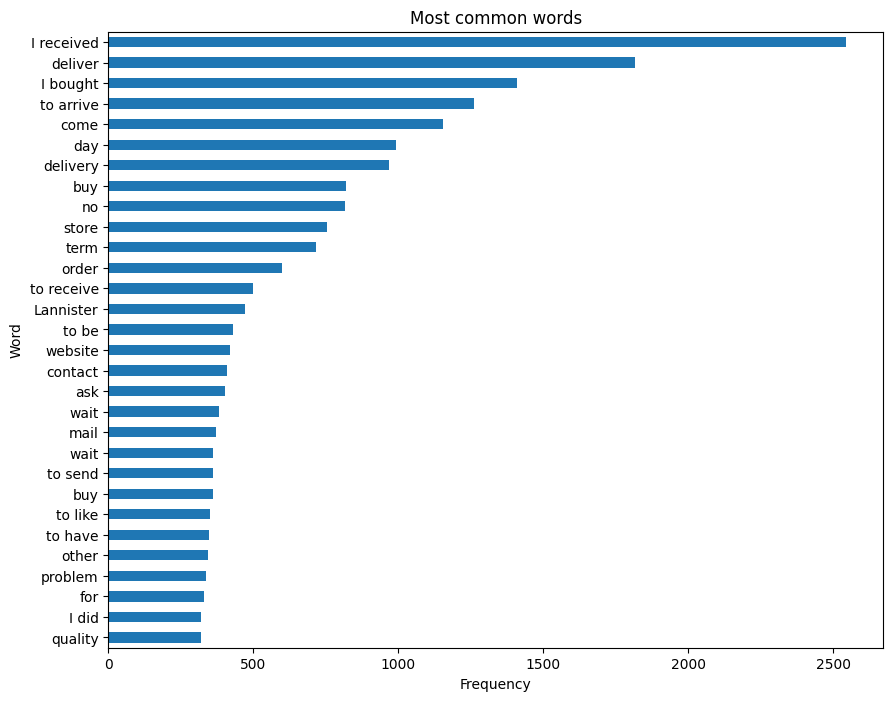

In [16]:
top_word_counts_pd.sort_values("count").plot.barh(
    x="translated_words",
    y="count",
    legend=False,
    figsize=(10, 8)
)

plt.xlabel("Frequency")
plt.ylabel("Word")
plt.title("Most common words")
plt.show()

In [17]:
vectorizer = CountVectorizer(
    ngram_range=(3,3),
    min_df=5
)

In [ ]:
matrix = vectorizer.fit_transform(
    one_point_reviews["processed_text"]
)

In [ ]:
counts = matrix.sum(axis=0).A1
bigrams = vectorizer.get_feature_names_out()

In [ ]:
bigram_df = pd.DataFrame({
    "bigram": bigrams,
    "count": counts  
})
bigram_df = bigram_df.sort_values("count", ascending=False)

In [ ]:
top_30_bigram_df = bigram_df.head(30)

In [ ]:
top_30_bigram_df["translated_bigram"] = top_30_bigram_df["bigram"].apply(translator.translate)

In [ ]:
display(top_30_bigram_df)

,bigram,count,translated_bigram
114,prazo entrega dia,33,delivery deadline day
105,passar prazo entrega,27,pass delivery deadline
49,entrar contato comigo,23,get in touch with me
96,nota fiscal emitir,22,issue invoice
93,ninguém entrar contato,19,no one contact
35,cumprir prazo entrega,19,meet delivery deadline
47,emitir nota fiscal,18,issue invoice
125,receber dinheiro volta,18,receive money back
43,dia prazo entrega,17,delivery deadline day
53,entrar contato loja,16,contact store


In [ ]:
sample = one_point_reviews.sample(150, random_state=42)

In [ ]:
display(sample[["review_comment_message", "processed_text"]])

,review_comment_message,processed_text
12095,Foi enviado produto Diferente daquele do anúnc...,enviar produto diferente anúncio solicitar dev...
66898,Não comprem desta loja! Tentei fazer o cancela...,compr loja cancelamento compra atender recusar...
60018,Excelente,excelente
47646,O jogo de bolas de bilhar que comprei é totalm...,jogo bola bilhar compr totalmente diferente en...
61344,material ruim. sem garantia,material ruim garantia
...,...,...
75884,Comprei 2 capas de travesseiro e um de colchão...,comprei capa travesseiro colchão chegar capa t...
28634,"Olá, a descrição do produto não corresponde co...",olá descrição produto corresponder modelo receber
24881,"Produto bem inferior as imagens, a grama veio ...",produto inferior imagem grama vir desfiada sol...
85466,Não recebi o produto e não tenho nenhuma notícia,recebi produto notícia
